# Smart Supermarket: Grocery Product Analytics and Recognition
**HCCDA-AI capstone project** · combines all four Huawei Cloud labs on one real dataset

| Part | Lab it applies | What it does here |
|---|---|---|
| 0 | Labs 1, 2, 4 (environment) | Gets the dataset; on ModelArts, sets up OBS and MoXing |
| 1 | Lab 2: Advanced Python | Regex parses the dataset index, magic methods model a product, threads with a mutex load 5,400 images |
| 2 | Lab 1: NumPy arrays | Array creation, properties, indexing, `all` / `any` / `where`, `newaxis` broadcasting, `np.save` |
| 3 | Lab 4: Goods recognition | Trains a model that recognizes 81 grocery products from real store photos, then predicts on test images |
| 4 | Lab 3: OCR General Table | Renders the results as a table image and reads it back with Huawei OCR General Table |

**Dataset:** [Grocery Store Dataset](https://github.com/marcusklasson/GroceryStoreDataset) (MIT license). 5,421 photos of fruit, vegetables, and packaged goods taken with a phone inside supermarkets, in 81 fine classes and 43 coarse classes, with official train / val / test splits.
Klasson, Zhang, and Kjellström, *A Hierarchical Grocery Store Image Dataset with Visual and Semantic Labels*, WACV 2019.

**Runs on:** local Python, Google Colab, or a ModelArts notebook. Cells marked **[ModelArts only]** or **[Huawei Cloud]** skip themselves when those services aren't available.

## Part 0: Setup

In [1]:
import os, re, time, json, threading, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_ROOT = "GroceryStoreDataset"
if not os.path.isdir(DATA_ROOT):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/marcusklasson/GroceryStoreDataset.git"], check=True)
DATA_DIR = os.path.join(DATA_ROOT, "dataset")

# On ModelArts, outputs go to the OBS-mounted folder from Lab 1 (/data/input); elsewhere to ./outputs
OUT_DIR = "/data/input" if os.path.isdir("/data/input") else "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

try:
    import moxing as mox          # exists only inside ModelArts
    ON_MODELARTS = True
except ImportError:
    ON_MODELARTS = False
print("Data:", DATA_DIR, "| Outputs:", OUT_DIR, "| ModelArts:", ON_MODELARTS)

Data: GroceryStoreDataset/dataset | Outputs: outputs | ModelArts: False


**[ModelArts only] Lab 1 and Lab 4 setup.** Before running on ModelArts:
1. OBS → **Parallel File Systems** → create one (AP-Singapore, Single-AZ, block public access, private) and add an `input` folder.
2. Create the notebook (`pytorch_1.12.1-cuda_10.2-py_3.9.11-ubuntu_20.04-x86_64`, CPU 2 vCPUs 8 GB, disk 10 GB).
3. Notebook → **Storage → Dynamic Storage**: mount path `/data/input`, pointing to your `input` folder.

Outputs then save straight into OBS, the same way `np.save("/data/input/...")` did in Lab 1.

## Part 1: Advanced Python (Lab 2)
### 1.1 Regular expressions: parsing the dataset index
Each line of `train.txt` looks like `train/Fruit/Apple/Golden-Delicious/Golden-Delicious_001.jpg, 0, 0`. The five methods from Lab 2 each do one job.

In [2]:
with open(os.path.join(DATA_DIR, "train.txt")) as f:
    line = f.readline().strip()
print("Raw line:", line)

# re.match: does the line start with a split name?
print("re.match  ->", re.match(r"train|val|test", line).span())

# re.search: find the image number anywhere in the line
print("re.search ->", re.search(r"_(\d+)\.jpg", line).group(1))

# re.split: break the path on '/' and ', '
print("re.split  ->", re.split(r"/|,\s*", line))

# re.sub: turn 'Golden-Delicious' into a readable name
print("re.sub    ->", re.sub(r"-", " ", "Golden-Delicious"))

# re.compile: one reusable pattern that pulls every field out of a line
PATTERN = re.compile(
    r"^(?P<split>\w+)/(?P<category>[^/]+)/(?P<coarse>[^/]+)/(?:(?P<fine>[^/]+)/)?"
    r"(?P<file>[^,]+),\s*(?P<class_id>\d+),\s*(?P<coarse_id>\d+)$")
print("re.compile->", PATTERN.match(line).groupdict())

Raw line: train/Fruit/Apple/Golden-Delicious/Golden-Delicious_001.jpg, 0, 0
re.match  -> (0, 5)
re.search -> 001
re.split  -> ['train', 'Fruit', 'Apple', 'Golden-Delicious', 'Golden-Delicious_001.jpg', '0', '0']
re.sub    -> Golden Delicious
re.compile-> {'split': 'train', 'category': 'Fruit', 'coarse': 'Apple', 'fine': 'Golden-Delicious', 'file': 'Golden-Delicious_001.jpg', 'class_id': '0', 'coarse_id': '0'}


In [3]:
def read_split(name):
    rows = []
    with open(os.path.join(DATA_DIR, f"{name}.txt")) as f:
        for raw in f:
            m = PATTERN.match(raw.strip())
            if m:
                d = m.groupdict()
                d["path"] = os.path.join(DATA_DIR, raw.split(",")[0].strip())
                rows.append(d)
    return pd.DataFrame(rows)

df = pd.concat([read_split(s) for s in ["train", "val", "test"]], ignore_index=True)
df[["class_id", "coarse_id"]] = df[["class_id", "coarse_id"]].astype(int)

classes = pd.read_csv(os.path.join(DATA_DIR, "classes.csv"))
classes.columns = ["class_name", "class_id", "coarse_name", "coarse_id", "iconic", "description"]
df = df.merge(classes[["class_id", "class_name", "coarse_name"]], on="class_id")

# re.findall: count how many product names are multi-word ("Golden-Delicious" -> 2 words)
words = classes["class_name"].apply(lambda n: len(re.findall(r"[A-Za-z]+", n)))
print(f"{len(df)} images | {df.class_id.nunique()} fine classes | {df.coarse_id.nunique()} coarse classes")
print(f"{(words > 1).sum()} of {len(classes)} product names have more than one word")
df.groupby("split").size()

5421 images | 81 fine classes | 43 coarse classes
53 of 81 product names have more than one word


split
test     2485
train    2640
val       296
dtype: int64

### 1.2 Magic methods: a `Product` class
`__init__` sets the attributes, `__str__` gives the shopper-friendly text, `__repr__` gives the developer view, and `__len__` / `__lt__` let Python's `len()` and `sorted()` work on products.

In [4]:
class Product(object):
    def __init__(self, name, category, coarse, images):
        self.name = name
        self.category = category
        self.coarse = coarse
        self.images = images

    def __str__(self):
        return "%s (%s > %s)" % (re.sub(r"-", " ", self.name), self.category, self.coarse)

    def __repr__(self):
        return "Product(name=%r, images=%d)" % (self.name, len(self))

    def __len__(self):
        return len(self.images)

    def __lt__(self, other):
        return len(self) < len(other)

products = [Product(n, g.category.iloc[0], g.coarse_name.iloc[0], list(g.path))
            for n, g in df.groupby("class_name")]
p = products[0]
print(p)            # __str__
print(repr(p))      # __repr__
print(len(p))       # __len__
print("Most photographed:", repr(max(products)))   # __lt__ via max()
products[:3]

Alpro Blueberry Soyghurt (Packages > Soyghurt)
Product(name='Alpro-Blueberry-Soyghurt', images=61)
61
Most photographed: Product(name='Satsumas', images=143)


[Product(name='Alpro-Blueberry-Soyghurt', images=61),
 Product(name='Alpro-Fresh-Soy-Milk', images=58),
 Product(name='Alpro-Shelf-Soy-Milk', images=60)]

### 1.3 Multi-threading with a mutex: loading every image
As in Lab 2, several threads append to one shared result and a `threading.Lock()` stops them from colliding. Each image is shrunk to a 64×64 thumbnail for the NumPy analysis in Part 2.

In [5]:
THUMB = 64

def load_thumb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB").resize((THUMB, THUMB)), dtype=np.uint8)

def load_threaded(paths, n_threads=4):
    results = [None] * len(paths)
    done = 0
    mutex = threading.Lock()

    def worker(idx_list):
        nonlocal done
        for i in idx_list:
            img = load_thumb(paths[i])
            mutex.acquire()      # lock
            results[i] = img
            done += 1
            mutex.release()      # unlock

    chunks = [list(range(k, len(paths), n_threads)) for k in range(n_threads)]
    threads = [threading.Thread(target=worker, args=(c,)) for c in chunks]
    for t in threads: t.start()
    for t in threads: t.join()
    return results, done

paths = list(df.path)
sample = paths[:400]
t0 = time.time(); _ = [load_thumb(p) for p in sample]; seq = time.time() - t0
t0 = time.time(); _, _ = load_threaded(sample); thr = time.time() - t0
print(f"400 images: sequential {seq:.2f}s | 4 threads {thr:.2f}s | speed-up {seq/thr:.1f}x")

t0 = time.time()
thumbs, done = load_threaded(paths)
print(f"Loaded {done} images with 4 threads in {time.time()-t0:.1f}s, shared counter = {done}")

400 images: sequential 0.28s | 4 threads 0.21s | speed-up 1.4x


Loaded 5421 images with 4 threads in 2.7s, shared counter = 5421


## Part 2: NumPy arrays (Lab 1)
### 2.1 Creating arrays and checking their properties

In [6]:
X = np.array(thumbs)                    # 4-D array: images x height x width x RGB
y = np.array(df.class_id)               # 1-D array of class IDs
print("dimension of X is:", X.ndim)
print("shape of X is:", X.shape)
print("size of X is:", X.size)
print("itemsize of X is:", X.itemsize, "byte (uint8)")
print("memory:", round(X.nbytes / 1e6, 1), "MB")
np.save(os.path.join(OUT_DIR, "task_02_labels"), y)

dimension of X is: 4
shape of X is: (5421, 64, 64, 3)
size of X is: 66613248
itemsize of X is: 1 byte (uint8)
memory: 66.6 MB


In [7]:
# The array-building functions from Lab 1, used for real jobs in this project
print("arange   -> class IDs:", np.arange(0, 81)[:10], "...")
print("linspace -> 5 brightness bands:", np.linspace(0, 255, 6).round(1))
print("logspace -> learning-rate grid:", np.logspace(-4, -1, 4))
print("zeros    -> empty 2x3 counter:\n", np.zeros((2, 3)))
print("eye      -> one-hot for 3 classes:\n", np.eye(3))
print("diag     -> per-split image counts:\n", np.diag(df.groupby("split").size().values))

arange   -> class IDs: [0 1 2 3 4 5 6 7 8 9] ...
linspace -> 5 brightness bands: [  0.  51. 102. 153. 204. 255.]
logspace -> learning-rate grid: [0.0001 0.001  0.01   0.1   ]
zeros    -> empty 2x3 counter:
 [[0. 0. 0.]
 [0. 0. 0.]]
eye      -> one-hot for 3 classes:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
diag     -> per-split image counts:
 [[2485    0    0]
 [   0 2640    0]
 [   0    0  296]]


### 2.2 Indexing and slicing

In [8]:
counts = np.bincount(y, minlength=81)           # images per class (1-D)
print("images for class 5:", counts[5])
print("classes 3-4:", counts[3:5])
print("first 5 classes:", counts[:5])
print("last class:", counts[-1])

img = X[0]                                     # one image (3-D)
print("\nimage shape:", img.shape)
print("top-left pixel, all channels:", img[0, 0])
print("centre 2x2 block, red channel:\n", img[31:33, 31:33, 0])
print("mean of each colour channel:", X[:, :, :, 0].mean().round(1), X[:, :, :, 1].mean().round(1), X[:, :, :, 2].mean().round(1))

images for class 5: 86
classes 3-4: [100 134]
first 5 classes: [ 96 123 123 100 134]
last class: 64

image shape: (64, 64, 3)
top-left pixel, all channels: [17  9  9]
centre 2x2 block, red channel:
 [[212 209]
 [209 208]]
mean of each colour channel: 134.6 101.1 65.7


### 2.3 `all()`, `any()`, `where()`

In [9]:
print("Every class has at least 1 photo? ", np.all(counts > 0))
print("Any class with over 100 photos?   ", np.any(counts > 100))

train_counts = np.bincount(y[(df.split == "train").values], minlength=81)
print(f"Training photos per class: min {train_counts.min()}, median {np.median(train_counts):.0f}, max {train_counts.max()}")
few = np.where(train_counts < 20)[0]           # classes with the least training data
np.save(os.path.join(OUT_DIR, "task_02_small_classes"), few)
print(f"\n{len(few)} classes have fewer than 20 training photos:")
print(classes.set_index("class_id").loc[few, "class_name"].tolist())

brightness = X.mean(axis=(1, 2, 3))
dark = np.where(brightness < 60)[0]
print(f"\n{len(dark)} very dark photos (mean pixel < 60), e.g. index {dark[:5]}")

Every class has at least 1 photo?  True
Any class with over 100 photos?    True
Training photos per class: min 16, median 30, max 70

7 classes have fewer than 20 training photos:
['God-Morgon-Apple-Juice', 'Arla-Sour-Cream', 'Asparagus', 'Cabbage', 'Ginger', 'Floury-Potato', 'Red-Beet']

4 very dark photos (mean pixel < 60), e.g. index [ 176  561 1002 3533]


### 2.4 `np.newaxis` broadcasting (the Lab 1 quiz)
The quiz showed that adding a size-1 axis lets arrays of different shapes combine. Here it normalizes every image by the dataset's per-channel mean and standard deviation, without reshaping anything by hand.

In [10]:
mean = X.reshape(-1, 3).mean(axis=0)            # shape (3,)
std = X.reshape(-1, 3).std(axis=0)              # shape (3,)
Xn = (X - mean[np.newaxis, np.newaxis, np.newaxis, :]) / std[np.newaxis, np.newaxis, np.newaxis, :]
print("channel mean:", mean.round(1), "| channel std:", std.round(1))
print("after normalising -> mean", Xn.mean().round(3), "| std", Xn.std().round(3))

channel mean: [134.6 101.1  65.7] | channel std: [60.6 54.9 51.4]


after normalising -> mean -0.0 | std 1.0


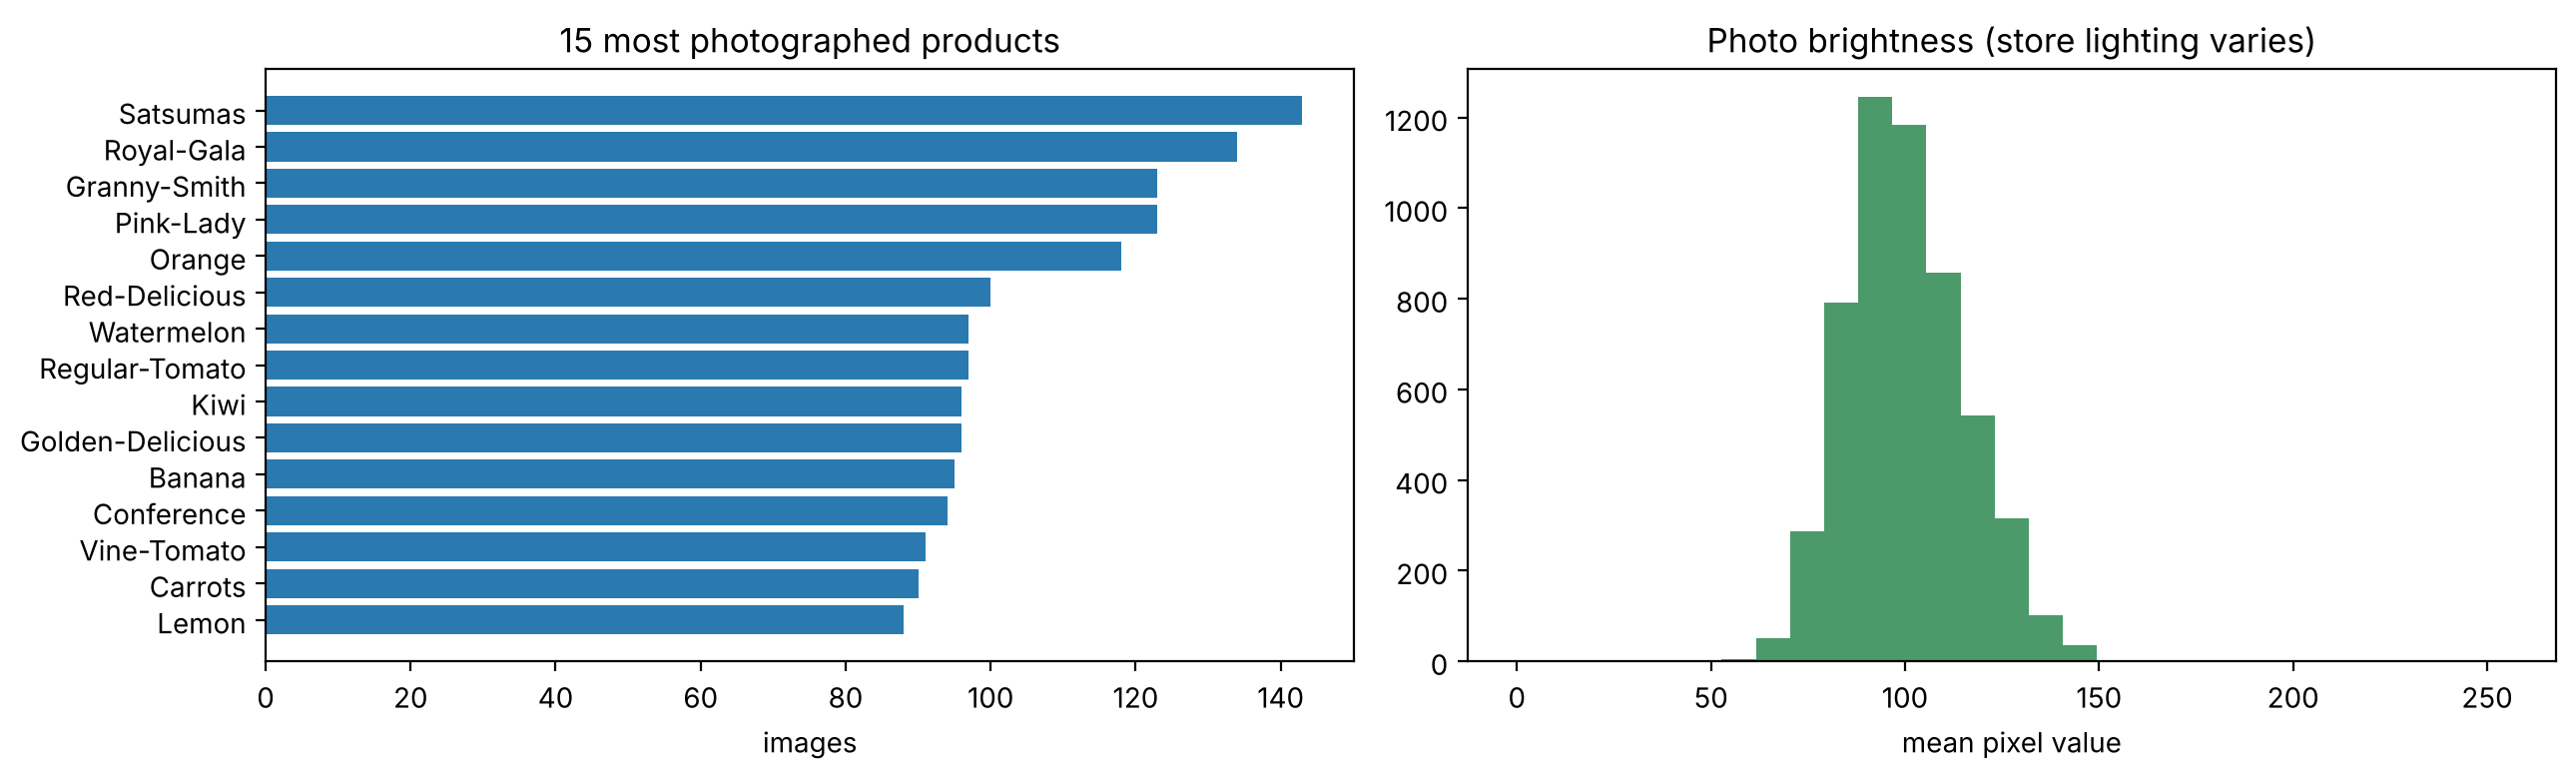

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
top = np.argsort(counts)[::-1][:15]
axes[0].barh(classes.set_index("class_id").loc[top, "class_name"][::-1], counts[top][::-1], color="#2a7ab0")
axes[0].set_title("15 most photographed products"); axes[0].set_xlabel("images")
axes[1].hist(brightness, bins=np.linspace(0, 255, 30), color="#4c9a6a")
axes[1].set_title("Photo brightness (store lighting varies)"); axes[1].set_xlabel("mean pixel value")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "eda.png"), dpi=110); plt.show()

## Part 3: Goods recognition (Lab 4)
Lab 4 deployed a ready-made model with ModelArts ExeML. Here the model is built in code with **transfer learning**, which is what ExeML does behind the scenes:
1. A MobileNetV2 network pre-trained on ImageNet turns each photo into 1,280 numbers that describe it (feature extraction).
2. A logistic regression classifier learns which product those numbers mean, using the official train split.
3. The val split picks the regularization strength, and the untouched test split gives the final score.

In [12]:
import torch
from torchvision import models, transforms
torch.set_num_threads(os.cpu_count())

weights = models.MobileNet_V2_Weights.IMAGENET1K_V1
backbone = models.mobilenet_v2(weights=weights, progress=False)
backbone.classifier = torch.nn.Identity()       # keep the 1,280-number feature vector
backbone.eval()
prep = weights.transforms()

def extract(paths, batch=64):
    feats = []
    with torch.no_grad():
        for i in range(0, len(paths), batch):
            ims = torch.stack([prep(Image.open(p).convert("RGB")) for p in paths[i:i+batch]])
            feats.append(backbone(ims).numpy())
    return np.concatenate(feats)

t0 = time.time()
F = extract(list(df.path))
np.save(os.path.join(OUT_DIR, "features_mobilenetv2"), F)
print("feature array:", F.shape, f"in {time.time()-t0:.0f}s")

feature array: (5421, 1280) in 150s


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

tr, va, te = [(df.split == s).values for s in ("train", "val", "test")]
scaler = StandardScaler().fit(F[tr])
Ftr, Fva, Fte = scaler.transform(F[tr]), scaler.transform(F[va]), scaler.transform(F[te])

best = None
for C in np.logspace(-3, 0, 4):                 # logspace grid, as in Lab 1
    clf = LogisticRegression(C=C, max_iter=2000).fit(Ftr, y[tr])
    acc = clf.score(Fva, y[va])
    print(f"C={C:<6.3g} validation accuracy {acc:.3f}")
    if best is None or acc > best[1]:
        best = (C, acc, clf)
C_best, _, clf = best
print("chosen C =", C_best)

C=0.001  validation accuracy 0.706


C=0.01   validation accuracy 0.743


C=0.1    validation accuracy 0.743


C=1      validation accuracy 0.736
chosen C = 0.01


### 3.1 Test results

In [14]:
pred = clf.predict(Fte)
coarse_of = classes.set_index("class_id")["coarse_id"].to_dict()
fine_acc = np.mean(pred == y[te])
coarse_acc = np.mean(np.vectorize(coarse_of.get)(pred) == np.vectorize(coarse_of.get)(y[te]))
top5 = np.mean([t in row for t, row in zip(y[te], np.argsort(clf.predict_proba(Fte), axis=1)[:, -5:])])
print(f"Test images: {te.sum()}")
print(f"Exact product (81 classes):  {fine_acc:.1%}")
print(f"Product type (43 classes):   {coarse_acc:.1%}")
print(f"Right answer in top 5:       {top5:.1%}")

Test images: 2485
Exact product (81 classes):  75.6%
Product type (43 classes):   85.5%
Right answer in top 5:       97.0%


In [15]:
names = classes.set_index("class_id")["class_name"]
test_df = df[te].copy()
test_df["pred"] = pred
test_df["correct"] = test_df.pred == test_df.class_id
by_cat = test_df.groupby("category").agg(test_images=("correct", "size"), accuracy=("correct", "mean")).round(3)
print(by_cat, "\n")

wrong = test_df[~test_df.correct]
confusions = (wrong.assign(true=wrong.class_id.map(names), predicted=wrong.pred.map(names))
              .groupby(["true", "predicted"]).size().sort_values(ascending=False).head(8))
print("Most common mix-ups:\n", confusions)

small = test_df.class_id.isin(few)
print(f"\nAccuracy on the {len(few)} classes with <20 training photos: {test_df[small].correct.mean():.1%}")
print(f"Accuracy on all other classes: {test_df[~small].correct.mean():.1%}")

            test_images  accuracy
category                         
Fruit              1117     0.731
Packages            781     0.709
Vegetables          587     0.867 

Most common mix-ups:
 true                      predicted               
Satsumas                  Orange                      31
Alpro-Vanilla-Soyghurt    Alpro-Blueberry-Soyghurt    19
Royal-Gala                Pink-Lady                   18
Mango                     Granny-Smith                16
Lime                      Granny-Smith                16
Yoggi-Vanilla-Yoghurt     Yoggi-Strawberry-Yoghurt    13
Yoggi-Strawberry-Yoghurt  Yoggi-Vanilla-Yoghurt       10
Orange                    Red-Grapefruit              10
dtype: int64

Accuracy on the 7 classes with <20 training photos: 65.3%
Accuracy on all other classes: 76.1%


### 3.2 Prediction on test photos
The same thing Lab 4's real-time service did when you uploaded the test image.

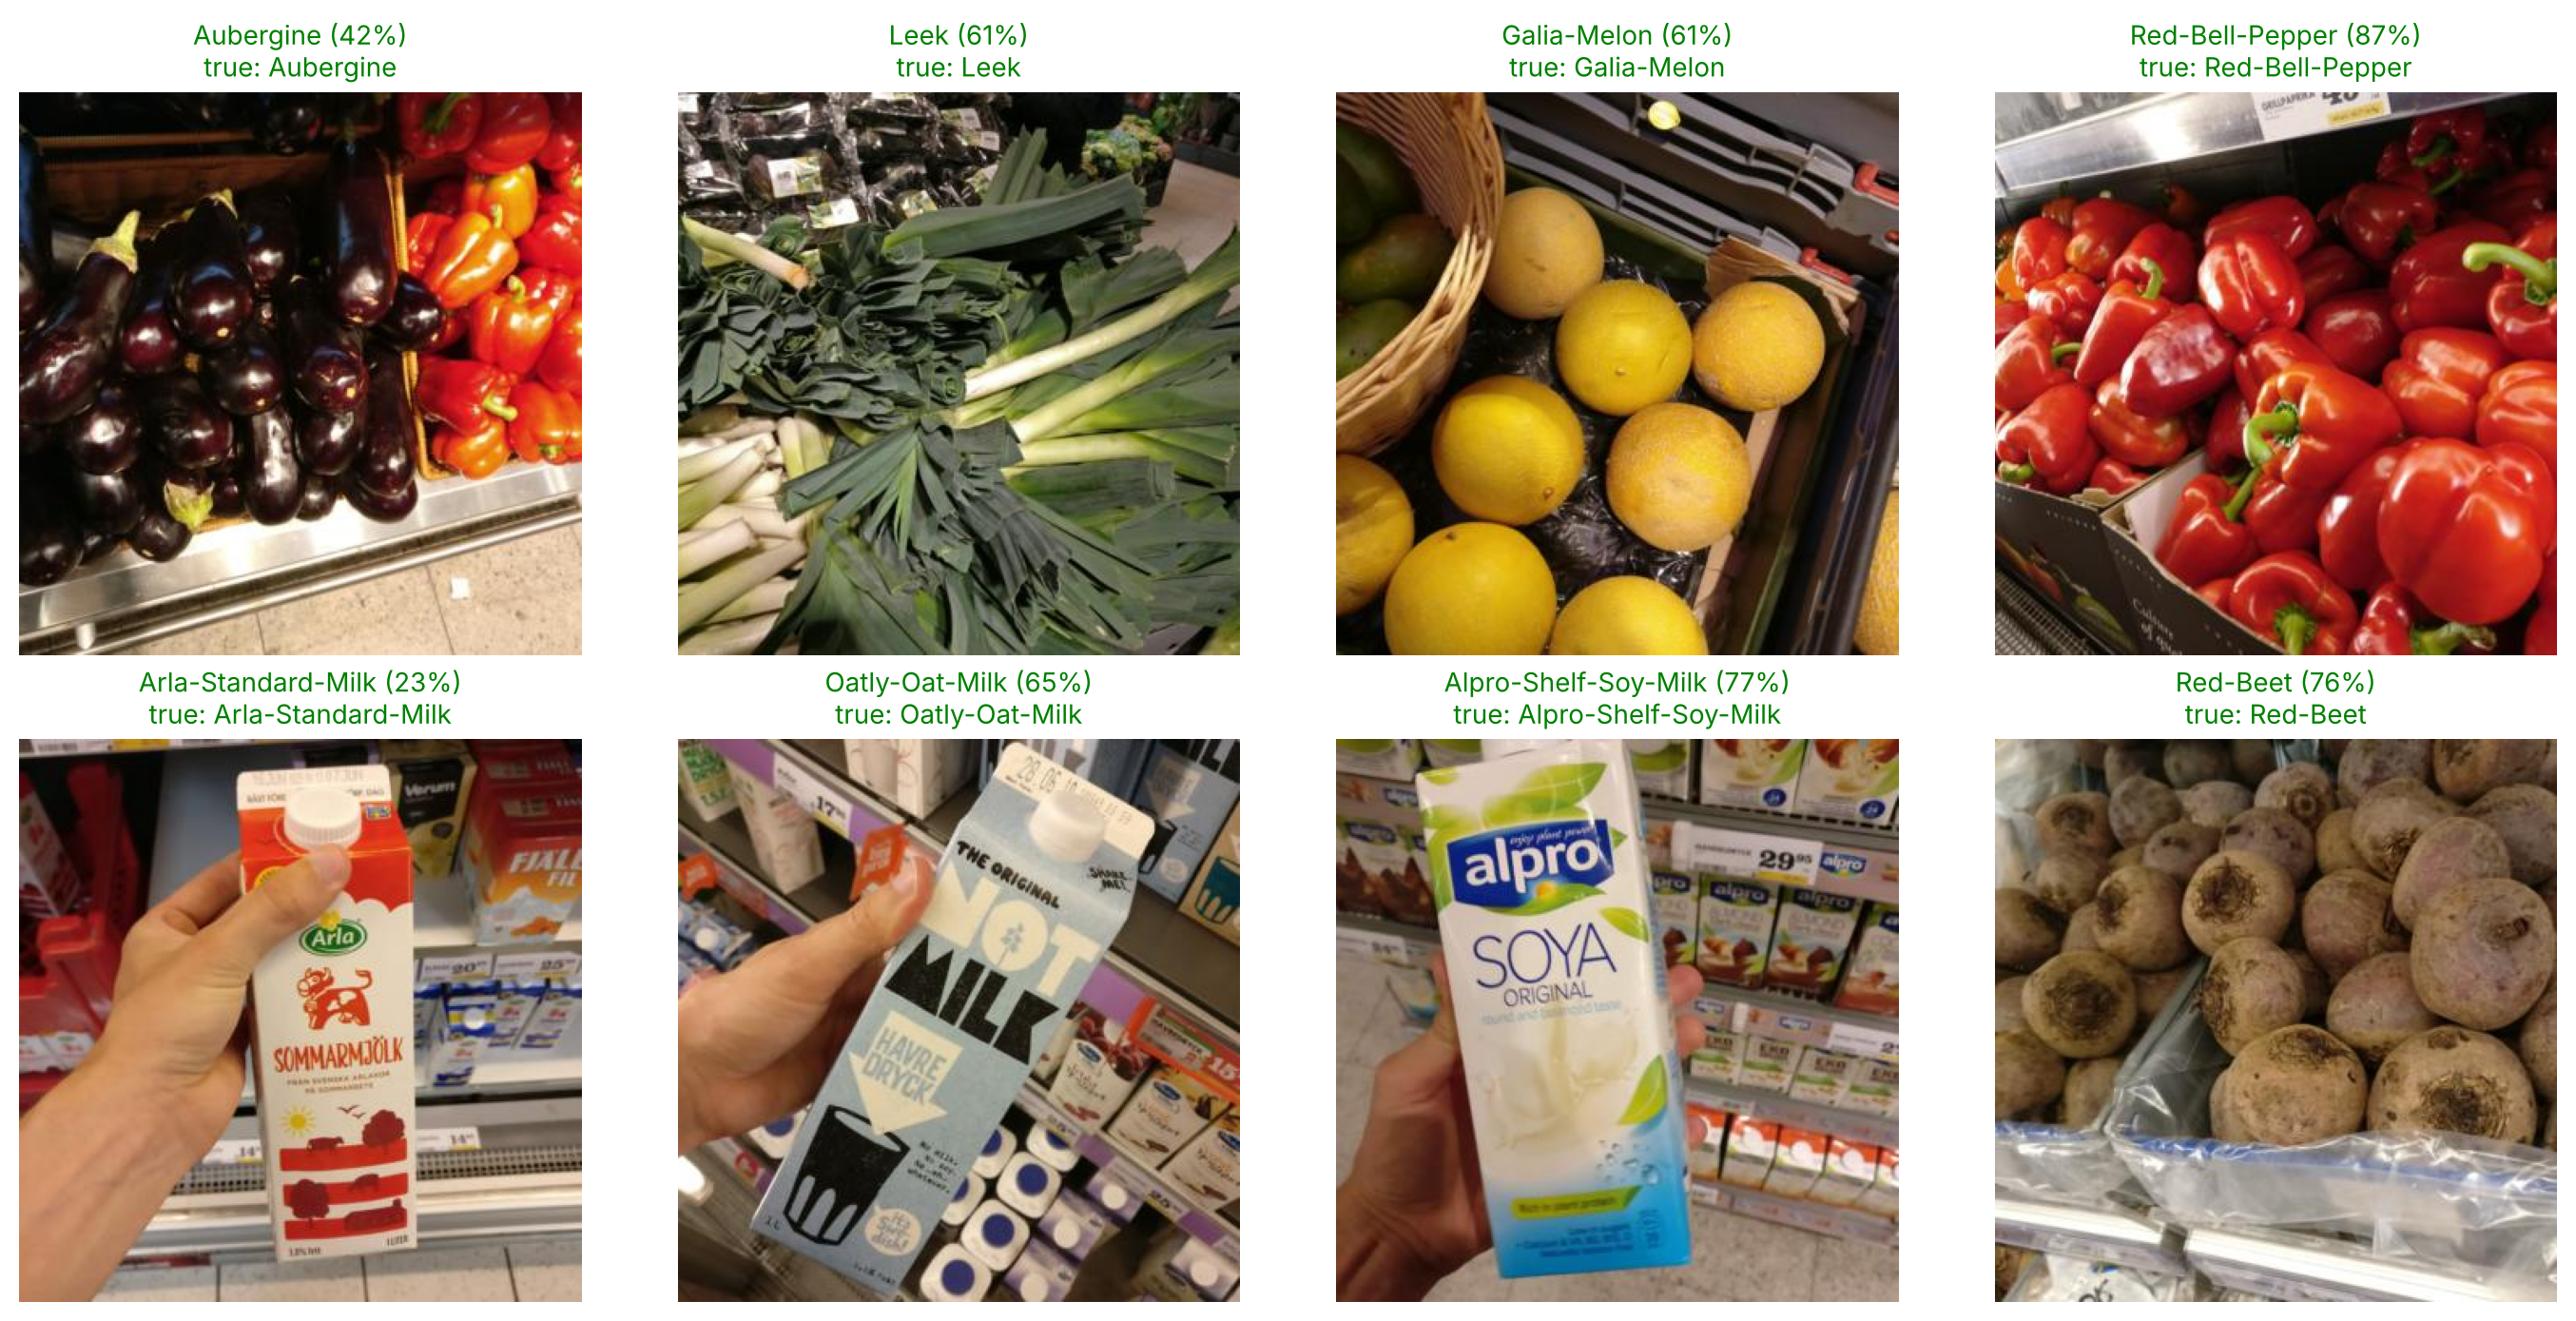

In [16]:
rng = np.random.default_rng(7)
idx = rng.choice(np.where(te)[0], 8, replace=False)
proba = clf.predict_proba(scaler.transform(F[idx]))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i, pr in zip(axes.ravel(), idx, proba):
    k = pr.argmax()
    ok = k == y[i]
    ax.imshow(Image.open(df.path[i]).convert("RGB")); ax.axis("off")
    ax.set_title(f"{names[k]} ({pr[k]:.0%})\ntrue: {names[y[i]]}", color="green" if ok else "red", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "predictions.png"), dpi=110); plt.show()

In [17]:
import joblib
joblib.dump({"scaler": scaler, "classifier": clf, "class_names": names.to_dict()},
            os.path.join(OUT_DIR, "grocery_classifier.joblib"))
print("saved model to", OUT_DIR)

saved model to outputs


**[ModelArts only] Deploying like Lab 4.** To serve this model the Lab 4 way:
1. Copy the outputs to OBS (cell at the end of Part 4).
2. ModelArts → **Model Management → Create Model**, meta model source **OBS**, pointing to the model folder.
3. **Deploy → Real-Time Services**, public resource pool → **Next → Submit**.
4. Open the service → **Prediction** → upload a test photo.

A custom model needs an inference script (`customize_service.py`) and `config.json` in the model folder; Lab 4's ExeML model came with them already.

## Part 4: OCR General Table (Lab 3)
### 4.1 Render the results table as an image
This creates a real table photo for OCR to read: the per-category test results from Part 3.

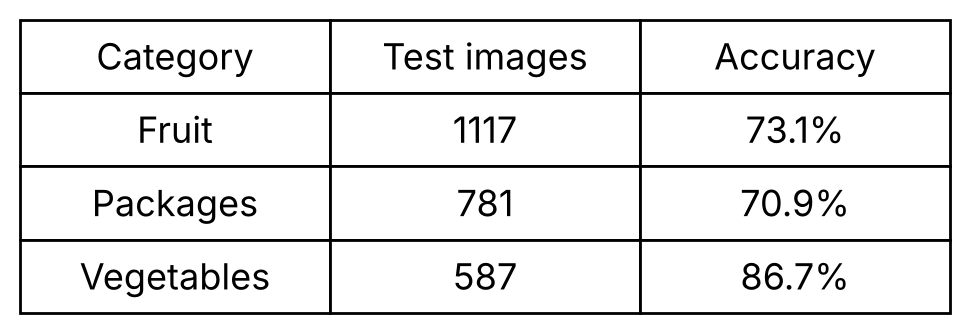

,Category,Test images,Accuracy
0,Fruit,1117,73.1%
1,Packages,781,70.9%
2,Vegetables,587,86.7%


In [18]:
table = by_cat.reset_index()
table["accuracy"] = (table.accuracy * 100).round(1).astype(str) + "%"
table.columns = ["Category", "Test images", "Accuracy"]

fig, ax = plt.subplots(figsize=(6, 1.6)); ax.axis("off")
tbl = ax.table(cellText=table.values, colLabels=table.columns, loc="center", cellLoc="center")
tbl.scale(1, 2.2); tbl.set_fontsize(13)
TABLE_IMG = os.path.join(OUT_DIR, "results_table.png")
plt.savefig(TABLE_IMG, dpi=200, bbox_inches="tight", facecolor="white"); plt.show()
table

### 4.2 [Huawei Cloud] Read it back with OCR General Table
Same SDK call as Lab 3, but sending the image as Base64 instead of a URL. Before running:
1. OCR console (AP-Singapore) → **General Table → Subscribe**.
2. Set your keys as environment variables, never in the code:
```bash
export HUAWEICLOUD_SDK_AK="your AK"
export HUAWEICLOUD_SDK_SK="your SK"
export HUAWEICLOUD_PROJECT_ID="your AP-Singapore project ID"
```
3. `pip install huaweicloudsdkcore huaweicloudsdkocr`

Without keys, this cell explains what's missing and moves on.

In [19]:
import base64

def ocr_general_table(image_path):
    from huaweicloudsdkcore.auth.credentials import BasicCredentials
    from huaweicloudsdkcore.http.http_config import HttpConfig
    from huaweicloudsdkocr.v1.region.ocr_region import OcrRegion
    from huaweicloudsdkocr.v1 import OcrClient, RecognizeGeneralTableRequest, GeneralTableRequestBody

    credentials = BasicCredentials(os.environ["HUAWEICLOUD_SDK_AK"], os.environ["HUAWEICLOUD_SDK_SK"],
                                   os.environ["HUAWEICLOUD_PROJECT_ID"])
    client = (OcrClient.new_builder()
              .with_http_config(HttpConfig.get_default_config())
              .with_credentials(credentials)
              .with_region(OcrRegion.value_of("ap-southeast-3"))
              .build())
    with open(image_path, "rb") as f:
        img_b64 = base64.b64encode(f.read()).decode()
    request = RecognizeGeneralTableRequest()
    request.body = GeneralTableRequestBody(image=img_b64, return_excel=True)
    return client.recognize_general_table(request).to_dict()

def table_from_ocr(result):
    cells = {}
    for region in result["result"]["words_region_list"]:
        if region["type"] != "table":
            continue
        for block in region["words_block_list"]:
            cells[(block["rows"][0], block["columns"][0])] = block["words"]
    n_r = max(r for r, _ in cells) + 1; n_c = max(c for _, c in cells) + 1
    grid = [[cells.get((r, c), "") for c in range(n_c)] for r in range(n_r)]
    return pd.DataFrame(grid[1:], columns=grid[0])

needed = ["HUAWEICLOUD_SDK_AK", "HUAWEICLOUD_SDK_SK", "HUAWEICLOUD_PROJECT_ID"]
missing = [k for k in needed if not os.environ.get(k)]
if missing:
    print("Skipped OCR: set", ", ".join(missing), "and subscribe to General Table in AP-Singapore.")
else:
    result = ocr_general_table(TABLE_IMG)
    ocr_df = table_from_ocr(result)
    display(ocr_df)
    excel_b64 = result["result"].get("excel")
    if excel_b64:                                   # Lab 3 API option: Base64 Excel file
        with open(os.path.join(OUT_DIR, "ocr_results.xlsx"), "wb") as f:
            f.write(base64.b64decode(excel_b64))
    match = (ocr_df.astype(str).values == table.astype(str).values).mean()
    print(f"OCR matched {match:.0%} of the original table's cells")

Skipped OCR: set HUAWEICLOUD_SDK_AK, HUAWEICLOUD_SDK_SK, HUAWEICLOUD_PROJECT_ID and subscribe to General Table in AP-Singapore.


### 4.3 [ModelArts only] Copy everything to OBS with MoXing (Labs 2 and 4)
Replace `obs://your-bucket` with your bucket from the OBS console.

In [20]:
OBS_PATH = "obs://your-bucket/Smart_Supermarket"
if ON_MODELARTS and OUT_DIR != "/data/input":
    mox.file.copy_parallel(OUT_DIR, OBS_PATH)
    print("copied", OUT_DIR, "->", OBS_PATH)
elif ON_MODELARTS:
    print("Outputs are already in OBS through the /data/input mount.")
else:
    print("Not on ModelArts. Outputs are in", os.path.abspath(OUT_DIR))
    print(sorted(os.listdir(OUT_DIR)))

Not on ModelArts. Outputs are in /home/claude/project/outputs
['eda.png', 'features_mobilenetv2.npy', 'grocery_classifier.joblib', 'predictions.png', 'results_table.png', 'task_02_labels.npy', 'task_02_small_classes.npy']


## Summary
| Lab | Skill | How this project used it |
|---|---|---|
| Lab 2 | `re` module | Parsed 5,421 index lines into structured fields with one compiled pattern |
| Lab 2 | Magic methods | `Product` class with `__init__`, `__str__`, `__repr__`, `__len__`, `__lt__` |
| Lab 2 | Threads and mutex | Loaded every image with 4 threads writing to shared results under a lock |
| Lab 1 | NumPy | 4-D image array, properties, slicing, `bincount`, `all`/`any`/`where`, `newaxis` normalization, `np.save` |
| Lab 4 | Goods recognition | Transfer learning on 81 real grocery products, evaluated on the official test split |
| Lab 3 | OCR General Table | Read the results table back from an image and exported it to Excel |

**Lab 4 quiz, applied:** the quiz says more data and hyperparameter tuning improve a model. Part 3 tuned `C` on the val split, and Part 2 found the classes with the least training data (`np.where(train_counts < 20)`). Part 3.1 compares their test accuracy with the rest, which shows whether they are the first place to add photos. The biggest mix-ups are look-alike products (Satsumas vs Orange, vanilla vs blueberry yoghurt), so close-up photos of labels would help most there.